In [ ]:

# stdlib
import math
import random
from math import inf

# dependencies
import torch
import typing_extensions as tx
from torch import Tensor

# internals
from cornucopia.base import Transform, NonFinalTransform, FinalTransform
from cornucopia.baseutils import Returned, prepare_output, return_requires
from cornucopia.intensity import MulFieldTransform
from cornucopia.geometric import RandomAffineTransform
from cornucopia.random import Fixed, Sampler
from cornucopia.utils.warps import identity
from cornucopia.utils.smart_inplace import sqrt_, square_, abs_, mul_, exp_, sub_, add_
from cornucopia import ctx
from cornucopia import typing as cct



class ArrayCoilCombinationTransform(FinalTransform):
    """Apply coil sensitivities to an image and combine across coils."""

    def __init__(self, sens: Tensor, **kwargs) -> None:
        """
        Parameters
        ----------
        sens : (K, *spatial) tensor
            Complex coil sensitivities

        Other Parameters
        ----------------
        returns : [(list | dict) of] str
            See [`Transform`][cornucopia.base.Transform] for details.
            Default is `'uncombined'`.

            | Value          | Description                              |
            | -------------- | ---------------------------------------- |
            | `'sos'`        | Sum of square combined (magnitude) image |
            | `'uncombined'` | Uncombined (complex) coil images         |
            | `'sens'`       | Uncombined (complex) coil sensitivities  |
            | `'netsens'`    | Net (magnitude) coil sensitivity         |

        append, prefix, include, exclude, consume
            See [`Transform`][cornucopia.base.Transform] for details.
        """
        super().__init__(**kwargs)
        self.sens = sens

    def _xform(self, x: Tensor) -> Returned:
        sens = self.sens.to(x.device)
        uncombined = x * sens
        netsens = sqrt_(square_(sens.abs()).sum(0))[None]
        sos = sqrt_(square_(uncombined.abs()).sum(0))[None]
        return prepare_output(
            dict(input=x, sos=sos, output=uncombined,
                 uncombined=uncombined, netsens=netsens, sens=sens),
            self.returns)


class ArrayCoilTransform(NonFinalTransform):
    """Generate and apply random coil sensitivities (real or complex)"""

    Final = Next = ArrayCoilCombinationTransform
    """The transform type returned by `unroll`, `next` and `final`."""

    def __init__(
        self,
        ncoils: int = 8,
        fwhm: float = 0.5,
        diameter: float = 0.8,
        jitter: float = 0.01,
        unit: tx.Literal['fov', 'vox'] = 'fov',
        shape: cct.NumberOrSequence[int] = 4,
        sos: bool = True,
        *,
        shared=True,
        **kwargs
    ) -> None:
        """

        Parameters
        ----------
        ncoils : int
            Number of complex receiver channels
        fwhm : float
            Width of each receiver profile
        diameter : float
            Diameter of the ellipsoid on wich receivers are centered
        jitter : float
            Amount of jitter off the ellipsoid
        unit : {'fov', 'vox'}
            Unit of `fwhm`, `diameter`, `jitter`
        shape : [list of] int
            Number of control points for the underlying smooth component.

        Other Parameters
        ----------------
        shared
            See [`NonFinalTransform`][cornucopia.base.NonFinalTransform]
            for details.
        returns : [(list | dict) of] str
            See [`Transform`][cornucopia.base.Transform] for details.
            Default is `'uncombined'`.

            | Value          | Description                              |
            | -------------- | ---------------------------------------- |
            | `'sos'`        | Sum of square combined (magnitude) image |
            | `'uncombined'` | Uncombined (complex) coil images         |
            | `'sens'`       | Uncombined (complex) coil sensitivities  |
            | `'netsens'`    | Net (magnitude) coil sensitivity         |

        append, prefix, include, exclude, consume
            See [`Transform`][cornucopia.base.Transform] for details.
        """  # noqa: E501
        super().__init__(shared=shared, **kwargs)
        self.ncoils = ncoils
        self.fwhm = fwhm
        self.diameter = diameter
        self.jitter = jitter
        self.unit = unit
        self.shape = shape
        self.sos = sos

    def _unroll(self, x: Tensor, max_depth: int = inf) -> Transform:
        if max_depth == 0:
            return self

        ndim = x.dim() - 1
        backend = dict(dtype=x.dtype, device=x.device)
        fake_x = torch.ones([], **backend)
        fake_x = fake_x.expand([2*self.ncoils, *x.shape[1:]])

        smooth_bias = MulFieldTransform(shape=self.shape, vmin=-1, vmax=1)
        smooth_bias = smooth_bias(fake_x)
        phase = smooth_bias[::2].atan2(smooth_bias[1::2])
        magnitude = sqrt_(add_(smooth_bias[0::2].square(),
                               smooth_bias[1::2].square()))

        fov = torch.as_tensor(x.shape[1:], **backend)
        fwhm = self.fwhm
        if self.unit == 'fov':
            fwhm = fwhm * fov
        lam = (2.355 / fwhm) ** 2
        for k in range(self.ncoils):
            loc = torch.randn(ndim, **backend)
            loc /= loc.square().sum().sqrt_()
            loc = mul_(loc, self.diameter)
            if self.jitter:
                jitter = torch.rand(ndim, **backend)
                jitter = mul_(jitter, self.jitter)
                loc = add_(loc, jitter)
            loc = (1 + loc) / 2
            if self.unit == 'fov':
                loc = mul_(loc, fov)
            exp_bias = sub_(identity(x.shape[1:], **backend), loc)
            exp_bias = mul_(square_(exp_bias), lam).sum(-1)
            exp_bias = exp_(mul_(exp_bias, -0.5))
            if exp_bias.requires_grad:
                magnitude_k = magnitude[k].clone()
                magnitude[k].copy_(magnitude_k * exp_bias)
            else:
                mul_(magnitude[k], exp_bias)

        sens = mul_(exp_(1j * phase), magnitude)
        return self.Next(
            sens, **self.get_prm()
        ).unroll(x, max_depth-1)


class SumOfSquaresTransform(FinalTransform):
    """Compute the sum-of-squares across coils/channels"""

    def _xform(self, x: Tensor) -> Tensor:
        return sqrt_(square_(abs_(x)).sum(0, keepdim=True))


class IntraScanMotionFinalTransform(FinalTransform):
    """Apply pre-computed intra-scan motion"""

    def __init__(
        self,
        motion: FinalTransform,
        patterns: Tensor,
        sens: tx.Optional[FinalTransform] = None,
        axis: int = -1,
        freq: bool = False,
        **kwargs
    ) -> None:
        """
        Parameters
        ----------
        motion : FinalTransform
            A transform that applies the motion to an image
        patterns : tensor
            Binary tensor of shape (N, X) indicating which frequencies/slices
            are acquired in each shot. N is the number of shots, X is the
            number of frequencies/slices along the motion axis.
        sens : FinalTransform
            A transform that generates a set of complex sensitivity profiles.
        axis : int
            Axis along which shots are acquired (slice or phase-encode)
        freq : bool
            Motion happens across a phase-encode direction, which means
            that the k-space is build from pieces with different object
            position. This typically happens in "3D" acquisitions.
            If False, motion happens along the slice direction ("2D"
            acquisition).

        Other Parameters
        ----------------
        returns : [(list | dict) of] str
            See [`Transform`][cornucopia.base.Transform] for details.
            Default is `'sos'`.

            | Value          | Description                              | Shape         |
            | -------------- | ---------------------------------------- | ------------- |
            | `'sos'`        | Sum of square combined (magnitude) image | `(C,X,Y,Z)`   |
            | `'uncombined'` | Uncombined (complex) coil images         | `(K,X,Y,Z)`   |
            | `'sens'`       | Uncombined (complex) coil sensitivities  | `(K,X,Y,Z)`   |
            | `'netsens'`    | Net (magnitude) coil sensitivity         | `(1,X,Y,Z)`   |
            | `'flow'`       | Displacement field in each shot          | `(N,3,X,Y,Z)` |
            | `'matrix'`     | Rigid matrix in each shot                | `(N,4,4)`     |
            | `'pattern'`    | Frequencies acquired in each shot        | `(N,X)`       |

        append, prefix, include, exclude, consume
            See [`Transform`][cornucopia.base.Transform] for details.
        """
        super().__init__(**kwargs)
        self.motion = motion
        self.patterns = patterns
        self.sens = sens
        self.axis = axis
        self.freq = freq

    # def _xform(self, x: Tensor) -> Returned:
    #     motions = self.motion
    #     patterns = self.patterns.to(x.device)

    #     if self.sens:
    #         assert len(x) == 1
    #         with ctx.returns(self.sens, ['sens', 'netsens']):
    #             sens, netsens = self.sens(x)
    #         # sens = self.sens.to(x.device)
    #         # netsens = sens.abs().square_().sum(0).sqrt_()[None]
    #         y = x.new_empty([len(sens), *x.shape[1:]],
    #                         dtype=torch.complex64)
    #     else:
    #         ydtype = torch.complex64 if self.freq else x.dtype
    #         y = torch.empty_like(x, dtype=ydtype)
    #         sens = netsens = None

    #     x = x.movedim(self.axis, 1)
    #     y = y.movedim(self.axis, 1)

    #     matrix, flow = [], []
    #     returned = return_requires(self.returns)
    #     returns = dict(moved='output')
    #     if 'matrix' in returned:
    #         returns['matrix'] = 'matrix'
    #     if 'flow' in returned:
    #         returns['flow'] = 'flow'
    #     for motion_trf, pattern in zip(motions, patterns):
    #         with ctx.returns(motion_trf, returns):
    #             moved = motion_trf(x)
    #         matrix.append(moved.get('matrix', None))
    #         flow.append(moved.get('flow', None))
    #         moved = moved['moved']
    #         if sens is not None:
    #             moved = moved * sens
    #         if self.freq:
    #             moved = torch.fft.ifftshift(moved)
    #             moved = torch.fft.fft(moved, dim=1)
    #             moved = torch.fft.fftshift(moved)
    #         # NOTE: In torch < 1.*:
    #         #   >> y[:, pattern] = moved[:, pattern]
    #         #   RuntimeError: index does not support automatic
    #         #   differentiation for outputs with complex dtype.
    #         # Use torch.where instead.
    #         y = torch.where(pattern[None], y, moved)

    #     if self.freq:
    #         y = torch.fft.ifftshift(y)
    #         y = torch.fft.ifft(y, dim=1)
    #         y = torch.fft.fftshift(y)

            
    #         # # plot the frequency domain representation of the image after motion
    #         # import matplotlib.pyplot as plt
    #         # print("y shape:", y.shape)
    #         # plt.figure(figsize=(10, 10))
    #         # plt.subplot(1, 2, 1)
    #         # plt.imshow(y.abs().squeeze(), cmap='gray', interpolation='nearest')
    #         # plt.axis('off')
    #         # plt.title('Frequency domain representation after motion')
    #         # plt.subplot(1, 2, 2)
    #         # plt.imshow(y.abs().squeeze(), cmap='gray', interpolation='nearest')
    #         # plt.axis('off')
    #         # plt.title('Frequency domain representation after motion')
    #         # plt.show()



    #     y = y.movedim(1, self.axis)
    #     x = x.movedim(1, self.axis)


    #     sos = sqrt_(square_(y.abs()).sum(0, keepdim=True))

    def _xform(self, x: Tensor) -> Returned:
        motions = self.motion
        patterns = self.patterns.to(x.device)
        ndim = x.dim()
        axis = self.axis % ndim

        if self.sens:
            assert len(x) == 1
            with ctx.returns(self.sens, ['sens', 'netsens']):
                sens, netsens = self.sens(x)
            y = x.new_zeros([len(sens), *x.shape[1:]], dtype=torch.complex64)
        else:
            ydtype = torch.complex64 if self.freq else x.dtype
            y = torch.zeros_like(x, dtype=ydtype)
            sens = netsens = None

        # máscara con forma (1, ..., n, ..., 1) alineada con `axis`
        mask_shape = [1] * ndim
        mask_shape[axis] = -1

        def fft(t):
            t = torch.fft.ifftshift(t, dim=axis)
            t = torch.fft.fft(t, dim=axis)
            return torch.fft.fftshift(t, dim=axis)

        def ifft(t):
            t = torch.fft.ifftshift(t, dim=axis)
            t = torch.fft.ifft(t, dim=axis)
            return torch.fft.fftshift(t, dim=axis)

        matrix, flow = [], []
        returned = return_requires(self.returns)
        returns = dict(moved='output')
        if 'matrix' in returned:
            returns['matrix'] = 'matrix'
        if 'flow' in returned:
            returns['flow'] = 'flow'
        for motion_trf, pattern in zip(motions, patterns):
            with ctx.returns(motion_trf, returns):
                moved = motion_trf(x)            # orientación original
            matrix.append(moved.get('matrix', None))
            flow.append(moved.get('flow', None))
            moved = moved['moved']
            if sens is not None:
                moved = moved * sens             # misma orientación que sens
            if self.freq:
                moved = fft(moved)
            # True -> frecuencias adquiridas en este shot -> tomar `moved`
            y = torch.where(pattern.reshape(mask_shape), moved, y)

        if self.freq:
            y = ifft(y)

        sos = sqrt_(square_(y.abs()).sum(0, keepdim=True))
      

        if 'matrix' in returned:
            matrix = torch.stack(matrix)
        else:
            matrix = None
        if 'flow' in returned:
            flow = torch.stack(flow)
        else:
            flow = None

        return prepare_output(
            dict(input=x, sos=sos, output=sos, uncombined=y, sens=sens,
                    netsens=netsens, pattern=patterns, flow=flow,
                    matrix=matrix),
            self.returns)


class IntraScanMotionTransform(NonFinalTransform):
    """Model intra-scan motion"""

    Final = Next = IntraScanMotionFinalTransform
    """The transform type returned by `unroll`, `next` and `final`."""

    def __init__(
        self,
        shots: int = 4,
        axis: int = -1,
        freq: bool = True,
        pattern: tx.Union[
            tx.Literal['sequential', 'random'],
            tx.Sequence[Tensor]
        ] = 'sequential',
        translations: tx.Union[Sampler, float] = 0.1,
        rotations: tx.Union[Sampler, float] = 15,
        sos: bool = True,
        coils: tx.Optional[Transform] = None,
        *,
        shared: tx.Union[str, bool] = 'channels',
        **kwargs
    ) -> None:
        """

        Parameters
        ----------
        shots : int
            Number of acquisition shots.
            The object is in a different position in each shot.
        axis : int
            Axis along which shots are acquired (slice or phase-encode)
        freq : bool
            Motion happens across a phase-encode direction, which means
            that the k-space is build from pieces with different object
            position. This typically happens in "3D" acquisitions.
            If False, motion happens along the slice direction ("2D"
            acquisition).
        pattern : {'sequential', 'random'} or list[tensor[bool or int]]
            k-space (or slice) sampling pattern. This argument encodes
            the frequencies (or slices) that are acquired in each shot.
            The 'sequential' options assumes that frequencies are
            acquired in order. The 'random' option assumes that frequencies
            are randomly distributed across shots.
        translations : Sampler or float
            Sampler (or upper-bound) for random translations (in % of FOV)
        rotations : Sampler or float
            Sampler (or upper-bound) for random rotations (in deg)
        sos : bool
            Whether to return the sum-of-squares combined image across coils.
        coils : Transform
            A transform that generates a set of complex sensitivity profiles

        Other Parameters
        ----------------
        shared
            See [`NonFinalTransform`][cornucopia.base.NonFinalTransform]
            for details.
        returns : [(list | dict) of] str
            See [`Transform`][cornucopia.base.Transform] for details.
            Default is `'sos'`.

            | Value          | Description                              | Shape         |
            | -------------- | ---------------------------------------- | ------------- |
            | `'sos'`        | Sum of square combined (magnitude) image | `(C,X,Y,Z)`   |
            | `'uncombined'` | Uncombined (complex) coil images         | `(K,X,Y,Z)`   |
            | `'sens'`       | Uncombined (complex) coil sensitivities  | `(K,X,Y,Z)`   |
            | `'netsens'`    | Net (magnitude) coil sensitivity         | `(1,X,Y,Z)`   |
            | `'flow'`       | Displacement field in each shot          | `(N,3,X,Y,Z)` |
            | `'matrix'`     | Rigid matrix in each shot                | `(N,4,4)`     |
            | `'pattern'`    | Frequencies acquired in each shot        | `(N,X)`       |

        append, prefix, include, exclude, consume
            See [`Transform`][cornucopia.base.Transform] for details.

        """  # noqa: E501
        super().__init__(shared=shared, **kwargs)
        self.shots = shots
        self.axis = axis
        self.pattern = pattern
        self.sos = sos
        self.coils = coils
        self.freq = freq
        self.motion = RandomAffineTransform(
            translations=translations, rotations=rotations,
            zooms=Fixed(0), shears=Fixed(0), bound='reflection')

    def get_pattern(
        self, n: int, device: tx.Optional[torch.device] = None
    ) -> Tensor:
        shots = min(self.shots, n)
        pattern = []
        if self.pattern == 'sequential':
            mask = torch.zeros(n, dtype=torch.bool, device=device)
            length = int(math.ceil(n/self.shots))
            for shot in range(shots):
                mask1 = mask.clone()
                mask1[shot*length:(shot+1)*length] = 1
                pattern.append(mask1)
            pattern = torch.stack(pattern)
        elif self.pattern == 'random':
            indices = list(range(n))
            random.shuffle(indices)
            mask = torch.zeros(n, dtype=torch.bool, device=device)
            length = int(math.ceil(n/self.shots))
            for shot in range(shots):
                mask1 = mask.clone()
                index1 = indices[shot*length:(shot+1)*length]
                mask1[index1] = 1
                pattern.append(mask1)
            pattern = torch.stack(pattern)
        elif isinstance(self.pattern, (list, tuple)):
            if max(map(max, self.pattern)) > 1:
                # indices
                mask = torch.zeros(n, dtype=torch.bool, device=device)
                for indices in self.pattern:
                    mask1 = mask.clone()
                    mask1[indices] = 1
                    pattern.append(mask1)
                pattern = torch.stack(pattern)
            else:
                pattern = torch.stack(pattern)
        else:
            assert torch.is_tensor(self.pattern)
            pattern = self.pattern
        return pattern.to(device, torch.bool)

    def _unroll(self, x: Tensor, max_depth: int = inf) -> Transform:
        # compute number of motion shots
        shots = min(self.shots, x.shape[self.axis])

        # sample motion parameters for each shot
        motion = []
        for shot in range(shots):
            motion_trf = self.motion.final(x)
            motion.append(motion_trf)

        # compute sampling pattern
        pattern = self.get_pattern(x.shape[self.axis], x.device)

        # sample coil sensitivities
        sens = None
        if self.coils:
            sens = self.coils.final(x)

        return self.Next(
            motion, pattern, sens, self.axis, self.freq, **self.get_prm()
        ).unroll(x, max_depth-1)



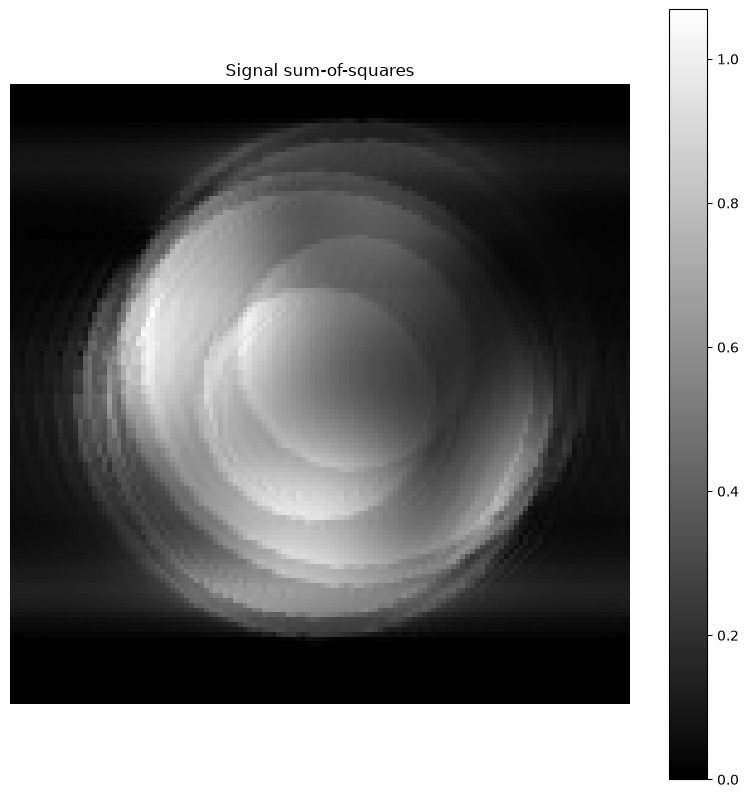

In [42]:
import torch
from cornucopia.utils.py import meshgrid_ij
# from cornucopia import (
#     IntraScanMotionTransform,
#     ArrayCoilTransform,
#     SmallIntraScanMotionTransform,
#     RandomSlicewiseAffineTransform,
# )
import  matplotlib.pyplot as plt

shape = [128, 128]
radius = torch.stack(meshgrid_ij(*[torch.arange(s).float() for s in shape]), -1)
radius -= (torch.as_tensor(shape).float() - 1) / 2
radius = radius.square().sum(-1).sqrt()

mag = torch.zeros_like(radius, dtype=torch.float32)
mag[radius < 48] = 1
mag[radius < 44] = 2
mag[radius < 24] = 3
mag = mag[None]  # channels dimension

# plt.figure(figsize=(10, 10))
# plt.imshow(mag.squeeze(), cmap='gray', interpolation='nearest')
# plt.axis('off')
# plt.title('Signal magnitude')
# plt.colorbar()
# plt.show()

# trf = IntraScanMotionTransform(coils=ArrayCoilTransform(), freq=True, shots=2, translations=1, rotations=15)
trf = IntraScanMotionTransform(coils=ArrayCoilTransform(), freq=True)
sos = trf(mag)

plt.figure(figsize=(10, 10))
plt.imshow(sos.squeeze(), cmap='gray', interpolation='nearest')
plt.axis('off')
plt.title('Signal sum-of-squares')
plt.colorbar()
plt.show()
